# Seasonal and Pollutant-Driven AQI Prediction Across Indian Cities Using Random Forest Regression

**Reference paper:** Gupta et al. (2023), *Journal of Environmental and Public Health*

**20 code cells** — one end-to-end workflow:

| # | Section |
|---|---|
| 01 | `01_imports` |
| 02–05 | `02_data_processing` |
| 06–10 | `03_data_visualization_eda` |
| 11–12 | `04_feature_engineering` |
| 13 | `05_train_test_split` |
| 14–17 | `06_model_training` |
| 18–19 | `07_model_testing` |
| 20 | `08_comparison_with_base_paper` + `09_save_models_and_summary` |

> **Run from inside `notebook/`.** `DATA_DIR = "../dataset"` resolves relative to the working directory.

## 01 — `01_imports`

In [25]:
import os, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.impute import KNNImputer

import shap

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

DATA_DIR  = "../dataset"
MODEL_DIR = "../models"
os.makedirs(MODEL_DIR, exist_ok=True)

print("Imports OK")
print("DATA_DIR :", os.path.abspath(DATA_DIR))
print("MODEL_DIR:", os.path.abspath(MODEL_DIR))

Imports OK
DATA_DIR : d:\Projects\air_quality_prediction\dataset
MODEL_DIR: d:\Projects\air_quality_prediction\models


## 02 — `02_data_processing` (load)

In [26]:
cd = pd.read_csv(os.path.join(DATA_DIR, "city_day.csv"))
print("Raw shape:", cd.shape)
print("Columns:", list(cd.columns))
display(cd.head())

Raw shape: (29531, 16)
Columns: ['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


## 03 — `02_data_processing` (parse date → month, season)

In [27]:
cd["Date"]  = pd.to_datetime(cd["Date"])
cd["month"] = cd["Date"].dt.month
cd["season"] = cd["month"].apply(
    lambda m: "winter"        if m in [12, 1, 2]   else
              "summer"        if m in [3, 4, 5]    else
              "monsoon"       if m in [6, 7, 8, 9] else
              "post-monsoon")

if "Xylene" in cd.columns:
    cd = cd.drop(columns=["Xylene"])

print("After date parsing:", cd.shape)

After date parsing: (29531, 17)


## 04 — `02_data_processing` (city filter — ≥ 500 valid AQI rows)

In [28]:
valid  = cd.dropna(subset=["AQI"])["City"].value_counts()
CITIES = valid[valid >= 500].index.tolist()
print(f"{len(CITIES)} cities selected: {CITIES}")
cd = cd[cd["City"].isin(CITIES)].copy()
print("Rows after city filter:", len(cd))

18 cities selected: ['Delhi', 'Bengaluru', 'Lucknow', 'Chennai', 'Hyderabad', 'Patna', 'Gurugram', 'Ahmedabad', 'Visakhapatnam', 'Amritsar', 'Jaipur', 'Thiruvananthapuram', 'Amaravati', 'Mumbai', 'Jorapokhar', 'Kolkata', 'Brajrajnagar', 'Talcher']
Rows after city filter: 27303


## 05 — `02_data_processing` (drop NaN AQI + impute pollutants)

In [29]:
POLLUTANTS = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
              "CO", "SO2", "O3", "Benzene", "Toluene"]

# ---- Drop rows where the TARGET (AQI) is NaN ----
before = len(cd)
cd = cd.dropna(subset=["AQI"]).reset_index(drop=True)
print(f"Dropped {before - len(cd)} rows with NaN AQI. Remaining: {len(cd)}")

# ---- Re-filter cities (some may fall below 500 after AQI drop) ----
counts = cd["City"].value_counts()
CITIES = counts[counts >= 500].index.tolist()
cd = cd[cd["City"].isin(CITIES)].copy()
print(f"{len(CITIES)} cities remaining: {CITIES}")
print("Rows after re-filter:", len(cd))

# ---- Impute pollutants per city ----
print("\nMissing % BEFORE imputation:")
print((cd[POLLUTANTS].isnull().sum() / len(cd) * 100).round(2).to_string())

frames = []
for city, g in cd.groupby("City"):
    g = g.sort_values("Date").copy()

    # forward-fill then back-fill within city
    g[POLLUTANTS] = g[POLLUTANTS].ffill().bfill()

    # columns KNN can handle vs. columns still fully NaN
    still_nan_cols = [c for c in POLLUTANTS if g[c].isnull().all()]
    knn_cols       = [c for c in POLLUTANTS if c not in still_nan_cols and g[c].isnull().any()]

    if knn_cols:
        imputed = KNNImputer(n_neighbors=5).fit_transform(g[knn_cols])
        g[knn_cols] = pd.DataFrame(imputed, columns=knn_cols, index=g.index)

    # fully-NaN columns → global median fallback
    for c in still_nan_cols:
        g[c] = cd[c].median()

    frames.append(g)

cd = pd.concat(frames).reset_index(drop=True)

print("\nMissing % AFTER imputation:")
print((cd[POLLUTANTS].isnull().sum() / len(cd) * 100).round(2).to_string())
print("Total missing remaining:", int(cd[POLLUTANTS].isnull().sum().sum()))
print("Final shape:", cd.shape)

Dropped 4496 rows with NaN AQI. Remaining: 22807
18 cities remaining: ['Delhi', 'Bengaluru', 'Lucknow', 'Chennai', 'Hyderabad', 'Patna', 'Gurugram', 'Ahmedabad', 'Visakhapatnam', 'Amritsar', 'Jaipur', 'Thiruvananthapuram', 'Amaravati', 'Mumbai', 'Jorapokhar', 'Kolkata', 'Brajrajnagar', 'Talcher']
Rows after re-filter: 22807

Missing % BEFORE imputation:
PM2.5       2.88
PM10       31.06
NO          1.43
NO2         1.38
NOx         8.11
NH3        28.07
CO          1.94
SO2         2.64
O3          2.81
Benzene    13.49
Toluene    22.08

Missing % AFTER imputation:
PM2.5      0.0
PM10       0.0
NO         0.0
NO2        0.0
NOx        0.0
NH3        0.0
CO         0.0
SO2        0.0
O3         0.0
Benzene    0.0
Toluene    0.0
Total missing remaining: 0
Final shape: (22807, 17)


## 06 — `03_data_visualization_eda` (Fig 1 — AQI distribution)

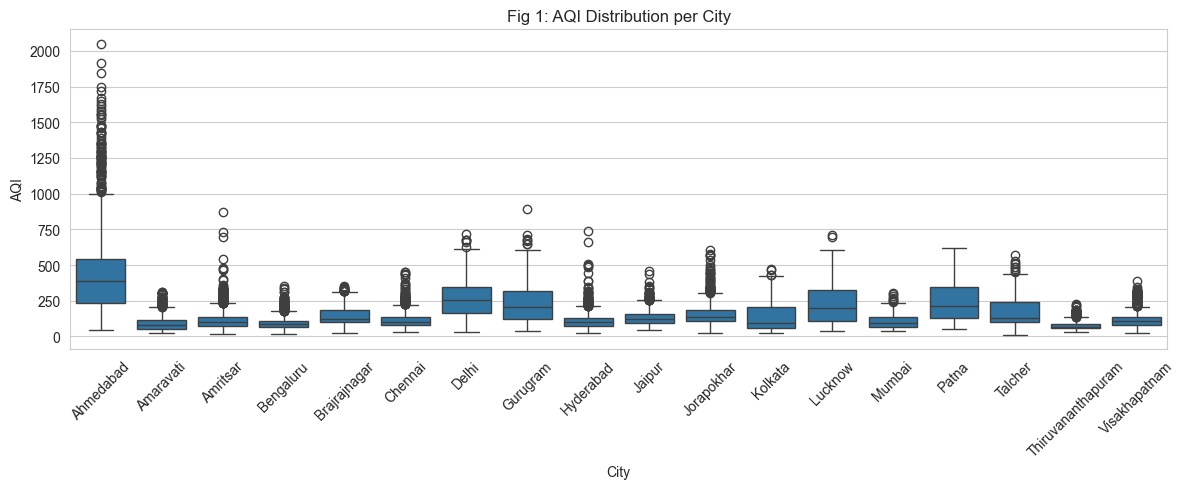

In [30]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=cd, x="City", y="AQI", ax=ax)
ax.set_title("Fig 1: AQI Distribution per City")
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

## 07 — `03_data_visualization_eda` (Fig 2 — monthly trend)

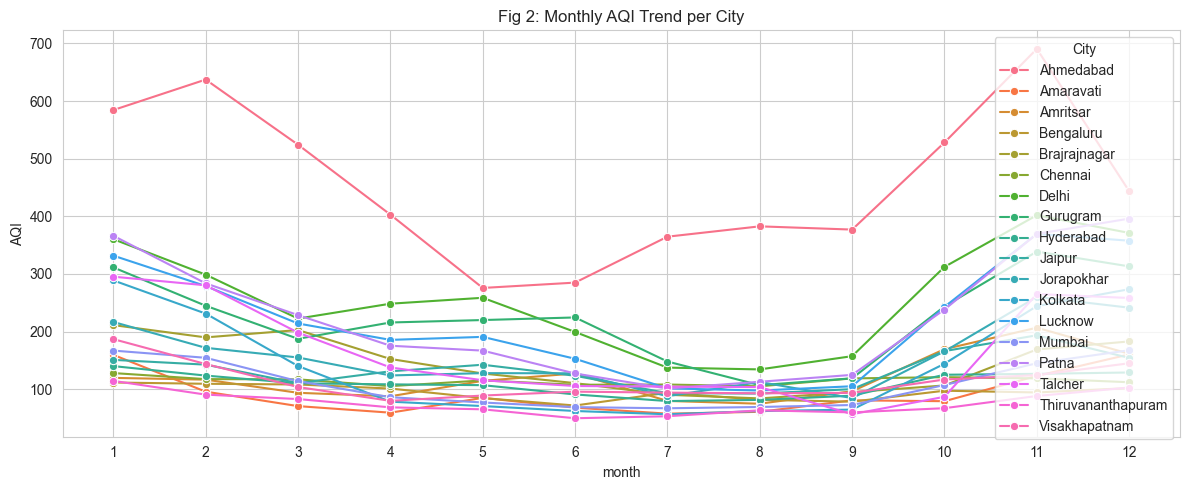

In [31]:
monthly = cd.groupby(["City", "month"])["AQI"].mean().reset_index()
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=monthly, x="month", y="AQI", hue="City", marker="o", ax=ax)
ax.set_title("Fig 2: Monthly AQI Trend per City")
ax.set_xticks(range(1, 13))
plt.tight_layout(); plt.show()

## 08 — `03_data_visualization_eda` (Fig 3 — seasonal bar)

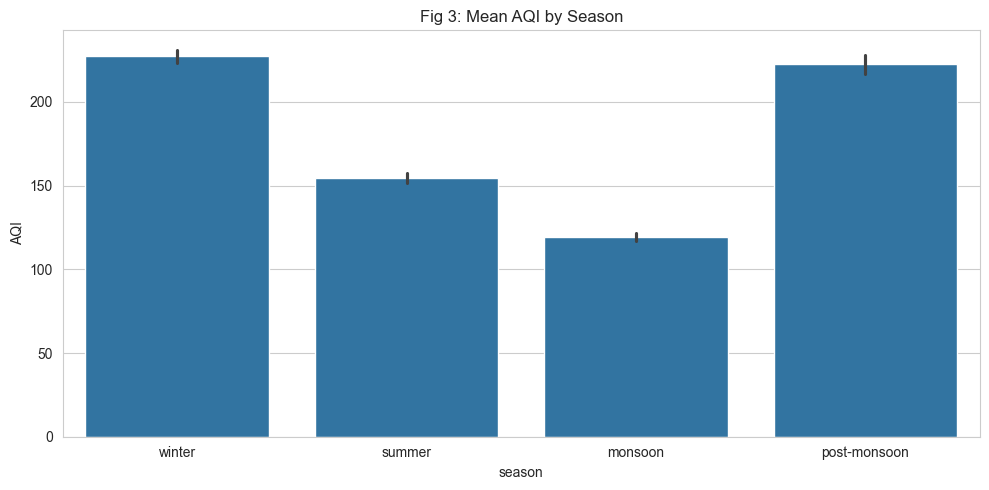

In [32]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=cd, x="season", y="AQI", estimator=np.mean,
            order=["winter", "summer", "monsoon", "post-monsoon"], ax=ax)
ax.set_title("Fig 3: Mean AQI by Season")
plt.tight_layout(); plt.show()

## 09 — `03_data_visualization_eda` (Fig 4 — correlation heatmap)

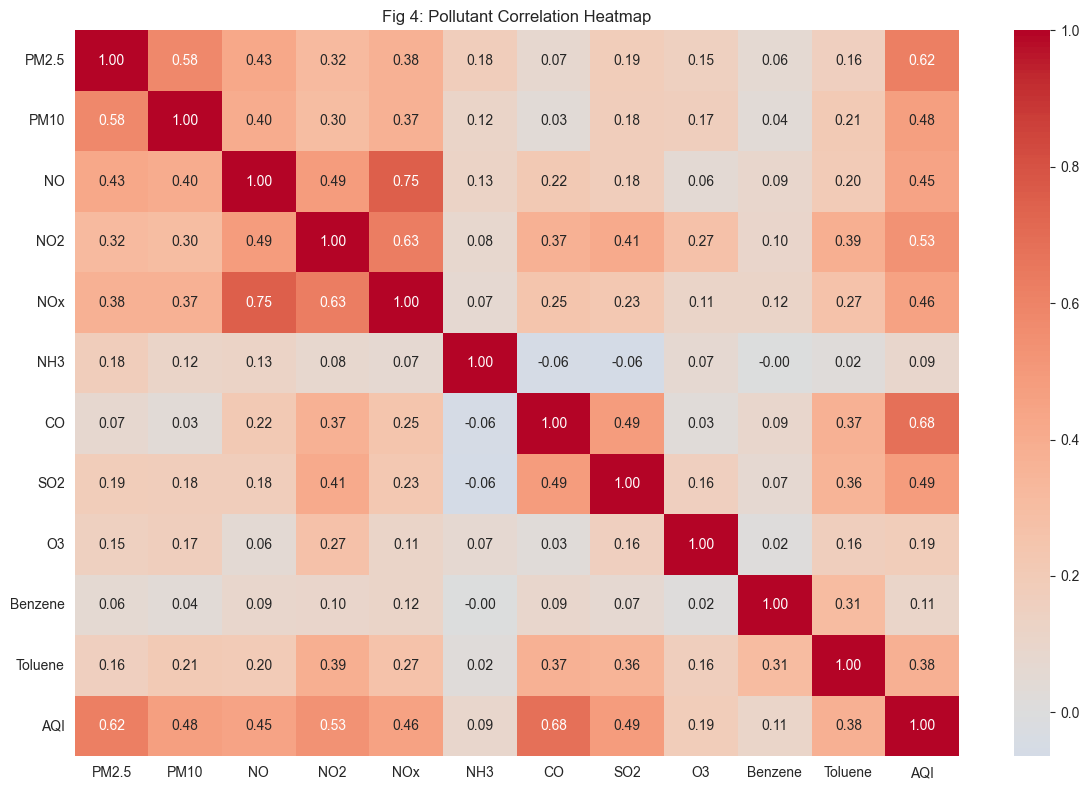

In [33]:
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(cd[POLLUTANTS + ["AQI"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, ax=ax)
ax.set_title("Fig 4: Pollutant Correlation Heatmap")
plt.tight_layout(); plt.show()

## 10 — `03_data_visualization_eda` (Fig 5 + sample rows)

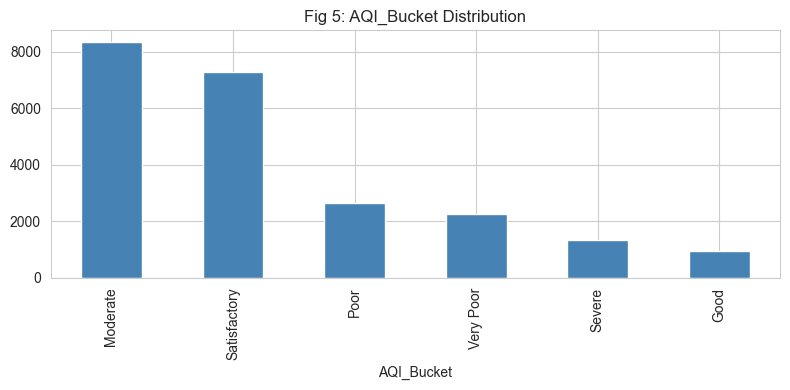

Sample rows per city:


,City,Date,PM2.5,PM10,NO2,AQI
0,Ahmedabad,2015-01-29,83.13,122.410,28.71,209.0
1,Ahmedabad,2015-01-30,79.84,122.410,28.68,328.0
1334,Amaravati,2017-11-25,81.40,124.500,20.50,184.0
1335,Amaravati,2017-11-26,78.32,129.060,26.00,197.0
2175,Amritsar,2017-02-28,12.45,13.800,8.05,52.0
2176,Amritsar,2017-03-01,19.52,21.880,6.02,31.0
3301,Bengaluru,2015-03-21,48.59,70.460,27.00,91.0
3302,Bengaluru,2015-03-22,47.38,70.460,22.39,120.0
5211,Brajrajnagar,2017-12-08,126.67,192.810,20.16,304.0
5212,Brajrajnagar,2017-12-09,105.11,154.390,18.40,291.0


In [34]:
fig, ax = plt.subplots(figsize=(8, 4))
cd["AQI_Bucket"].value_counts().plot.bar(ax=ax, color="steelblue")
ax.set_title("Fig 5: AQI_Bucket Distribution")
plt.tight_layout(); plt.show()

print("Sample rows per city:")
display(cd.groupby("City").head(2)[["City", "Date", "PM2.5", "PM10", "NO2", "AQI"]])

## 11 — `04_feature_engineering` (one-hot season)

In [35]:
cd = pd.get_dummies(cd, columns=["season"], prefix="season")
SEASON_COLS = [c for c in cd.columns if c.startswith("season_")]

FEATURES_POLL_ONLY = POLLUTANTS
FEATURES_FULL      = POLLUTANTS + ["month"] + SEASON_COLS

print("Poll-only :", FEATURES_POLL_ONLY)
print("Full      :", FEATURES_FULL)

Poll-only : ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']
Full      : ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'month', 'season_monsoon', 'season_post-monsoon', 'season_summer', 'season_winter']


## 12 — `04_feature_engineering` (feature summary)

In [36]:
display(cd[FEATURES_FULL + ["AQI"]].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
PM2.5,22807.0,71.45,66.32,0.04,30.52,50.91,84.58,914.94
PM10,22807.0,125.25,91.30,0.03,63.42,100.32,158.08,917.08
NO,22807.0,17.88,22.62,0.03,5.93,10.15,20.33,390.68
NO2,22807.0,29.85,24.94,0.01,12.72,23.06,38.98,362.21
NOx,22807.0,32.42,30.04,0.00,14.04,24.12,40.14,378.24
NH3,22807.0,27.71,28.11,0.02,9.71,17.82,39.69,352.89
CO,22807.0,2.46,7.31,0.00,0.61,0.95,1.52,175.81
SO2,22807.0,14.84,18.51,0.01,5.57,9.02,15.63,186.08
O3,22807.0,35.71,22.11,0.10,20.06,31.87,46.53,257.73
Benzene,22807.0,3.02,9.92,0.00,0.32,1.35,3.11,391.88


## 13 — `05_train_test_split` (chronological 80/20 per city)

In [37]:
splits = {}
for city in CITIES:
    g   = cd[cd["City"] == city].sort_values("Date").reset_index(drop=True)
    cut = int(len(g) * 0.8)
    tr, te = g.iloc[:cut], g.iloc[cut:]

    assert tr["AQI"].notna().all(), f"{city}: NaN in train AQI"
    assert te["AQI"].notna().all(), f"{city}: NaN in test AQI"
    assert len(tr) > 0 and len(te) > 0, f"{city}: empty split"

    splits[city] = {"train": tr, "test": te}
    print(f"{city:15s} train={len(tr):4d}  test={len(te):4d}")

print(f"\n{len(splits)} cities split successfully")

Delhi           train=1599  test= 400
Bengaluru       train=1528  test= 382
Lucknow         train=1514  test= 379
Chennai         train=1507  test= 377
Hyderabad       train=1504  test= 376
Patna           train=1167  test= 292
Gurugram        train=1162  test= 291
Ahmedabad       train=1067  test= 267
Visakhapatnam   train= 936  test= 235
Amritsar        train= 900  test= 226
Jaipur          train= 875  test= 219
Thiruvananthapuram train= 841  test= 211
Amaravati       train= 672  test= 169
Mumbai          train= 620  test= 155
Jorapokhar      train= 616  test= 155
Kolkata         train= 603  test= 151
Brajrajnagar    train= 570  test= 143
Talcher         train= 558  test= 140

18 cities split successfully


## 14 — `06_model_training` (Linear Regression baseline)

In [38]:
PARAM_GRID = {
    "n_estimators":      [200, 300],
    "max_depth":         [None, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf":  [1, 2],
    "max_features":      ["sqrt", None],
}

results, best = [], {}

for city in CITIES:
    tr, te = splits[city]["train"], splits[city]["test"]

    y_tr = tr["AQI"].to_numpy(dtype=float)
    y_te = te["AQI"].to_numpy(dtype=float)

    feats    = FEATURES_POLL_ONLY
    X_tr_raw = tr[feats].to_numpy(dtype=float)
    X_te_raw = te[feats].to_numpy(dtype=float)

    if np.isnan(X_tr_raw).any() or np.isnan(X_te_raw).any():
        raise ValueError(f"{city}: NaN in features — re-check cell 05")

    scaler = StandardScaler().fit(X_tr_raw)
    m      = LinearRegression().fit(scaler.transform(X_tr_raw), y_tr)
    pred   = m.predict(scaler.transform(X_te_raw))
    mae    = mean_absolute_error(y_te, pred)

    results.append({"City": city, "Model": "LR",
                    "Accuracy": (1 - mae) * 100,
                    "RMSE": float(np.sqrt(mean_squared_error(y_te, pred))),
                    "MAE": mae, "R2": r2_score(y_te, pred)})

    if city not in best:
        best[city] = {}
    best[city]["LR"] = {"model": m, "scaler": scaler, "features": feats}

print(f"LR done for {len(CITIES)} cities")

LR done for 18 cities


## 15 — `06_model_training` (Untuned RFR)

In [39]:
for city in CITIES:
    tr, te = splits[city]["train"], splits[city]["test"]

    y_tr = tr["AQI"].to_numpy(dtype=float)
    y_te = te["AQI"].to_numpy(dtype=float)

    feats    = FEATURES_POLL_ONLY
    X_tr_raw = tr[feats].to_numpy(dtype=float)
    X_te_raw = te[feats].to_numpy(dtype=float)

    scaler = StandardScaler().fit(X_tr_raw)
    m      = RandomForestRegressor(n_estimators=100, random_state=42,
                                   n_jobs=-1).fit(scaler.transform(X_tr_raw), y_tr)
    pred   = m.predict(scaler.transform(X_te_raw))
    mae    = mean_absolute_error(y_te, pred)

    results.append({"City": city, "Model": "RFR-untuned",
                    "Accuracy": (1 - mae) * 100,
                    "RMSE": float(np.sqrt(mean_squared_error(y_te, pred))),
                    "MAE": mae, "R2": r2_score(y_te, pred)})

    best[city]["RFR-untuned"] = {"model": m, "scaler": scaler, "features": feats}

print(f"Untuned RFR done for {len(CITIES)} cities")

Untuned RFR done for 18 cities


## 16 — `06_model_training` (Tuned RFR — pollutants only)

In [40]:
for city in CITIES:
    tr, te = splits[city]["train"], splits[city]["test"]

    y_tr = tr["AQI"].to_numpy(dtype=float)
    y_te = te["AQI"].to_numpy(dtype=float)

    feats    = FEATURES_POLL_ONLY
    X_tr_raw = tr[feats].to_numpy(dtype=float)
    X_te_raw = te[feats].to_numpy(dtype=float)

    scaler = StandardScaler().fit(X_tr_raw)
    gs = GridSearchCV(
        RandomForestRegressor(random_state=42, n_jobs=-1),
        PARAM_GRID,
        cv=TimeSeriesSplit(n_splits=3),
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    )
    gs.fit(scaler.transform(X_tr_raw), y_tr)

    m    = gs.best_estimator_
    pred = m.predict(scaler.transform(X_te_raw))
    mae  = mean_absolute_error(y_te, pred)

    results.append({"City": city, "Model": "RFR-tuned-poll",
                    "Accuracy": (1 - mae) * 100,
                    "RMSE": float(np.sqrt(mean_squared_error(y_te, pred))),
                    "MAE": mae, "R2": r2_score(y_te, pred)})

    best[city]["RFR-tuned-poll"] = {"model": m, "scaler": scaler, "features": feats}
    print(f"  {city:15s} tuned-poll done")

print(f"Tuned RFR (pollutants only) done for {len(CITIES)} cities")

  Delhi           tuned-poll done
  Bengaluru       tuned-poll done
  Lucknow         tuned-poll done
  Chennai         tuned-poll done
  Hyderabad       tuned-poll done
  Patna           tuned-poll done
  Gurugram        tuned-poll done
  Ahmedabad       tuned-poll done
  Visakhapatnam   tuned-poll done
  Amritsar        tuned-poll done
  Jaipur          tuned-poll done
  Thiruvananthapuram tuned-poll done
  Amaravati       tuned-poll done
  Mumbai          tuned-poll done
  Jorapokhar      tuned-poll done
  Kolkata         tuned-poll done
  Brajrajnagar    tuned-poll done
  Talcher         tuned-poll done
Tuned RFR (pollutants only) done for 18 cities


## 17 — `06_model_training` (Tuned RFR — pollutants + seasonal) ← main model

In [41]:
for city in CITIES:
    tr, te = splits[city]["train"], splits[city]["test"]

    y_tr = tr["AQI"].to_numpy(dtype=float)
    y_te = te["AQI"].to_numpy(dtype=float)

    feats    = FEATURES_FULL
    X_tr_raw = tr[feats].to_numpy(dtype=float)
    X_te_raw = te[feats].to_numpy(dtype=float)

    scaler = StandardScaler().fit(X_tr_raw)
    gs = GridSearchCV(
        RandomForestRegressor(random_state=42, n_jobs=-1),
        PARAM_GRID,
        cv=TimeSeriesSplit(n_splits=3),
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    )
    gs.fit(scaler.transform(X_tr_raw), y_tr)

    m    = gs.best_estimator_
    pred = m.predict(scaler.transform(X_te_raw))
    mae  = mean_absolute_error(y_te, pred)

    results.append({"City": city, "Model": "RFR-tuned-seasonal",
                    "Accuracy": (1 - mae) * 100,
                    "RMSE": float(np.sqrt(mean_squared_error(y_te, pred))),
                    "MAE": mae, "R2": r2_score(y_te, pred)})

    best[city]["RFR-tuned-seasonal"] = {"model": m, "scaler": scaler, "features": feats}
    print(f"  {city:15s} tuned-seasonal done")

print(f"Tuned RFR (pollutants + seasonal) done for {len(CITIES)} cities")

  Delhi           tuned-seasonal done
  Bengaluru       tuned-seasonal done
  Lucknow         tuned-seasonal done
  Chennai         tuned-seasonal done
  Hyderabad       tuned-seasonal done
  Patna           tuned-seasonal done
  Gurugram        tuned-seasonal done
  Ahmedabad       tuned-seasonal done
  Visakhapatnam   tuned-seasonal done
  Amritsar        tuned-seasonal done
  Jaipur          tuned-seasonal done
  Thiruvananthapuram tuned-seasonal done
  Amaravati       tuned-seasonal done
  Mumbai          tuned-seasonal done
  Jorapokhar      tuned-seasonal done
  Kolkata         tuned-seasonal done
  Brajrajnagar    tuned-seasonal done
  Talcher         tuned-seasonal done
Tuned RFR (pollutants + seasonal) done for 18 cities


## 18 — `07_model_testing` (metrics tables)

In [42]:
res_df = pd.DataFrame(results)

print("=" * 60)
print("ACCURACY (higher = better)")
print("=" * 60)
display(res_df.pivot(index="City", columns="Model", values="Accuracy").round(2))

print("\n" + "=" * 60)
print("RMSE (lower = better)")
print("=" * 60)
display(res_df.pivot(index="City", columns="Model", values="RMSE").round(3))

print("\n" + "=" * 60)
print("R² (higher = better)")
print("=" * 60)
display(res_df.pivot(index="City", columns="Model", values="R2").round(3))

print(f"\nRow count: {len(res_df)}  (expected {4 * len(CITIES)})")
print("Models:", sorted(res_df["Model"].unique()))

ACCURACY (higher = better)


Model,LR,RFR-tuned-poll,RFR-tuned-seasonal,RFR-untuned
City,,,,
Ahmedabad,-7490.30,-9551.51,-11144.95,-12074.54
Amaravati,-893.31,-881.50,-956.46,-877.40
Amritsar,-2271.83,-1706.83,-1688.64,-1873.17
Bengaluru,-729.98,-527.04,-504.79,-557.74
Brajrajnagar,-3255.56,-2426.21,-2428.53,-2496.73
Chennai,-7304.01,-1435.59,-1429.12,-1478.55
Delhi,-2875.70,-1900.69,-1932.60,-1931.40
Gurugram,-2790.95,-1982.45,-1951.44,-1967.36
Hyderabad,-1296.94,-944.92,-994.97,-950.11



RMSE (lower = better)


Model,LR,RFR-tuned-poll,RFR-tuned-seasonal,RFR-untuned
City,,,,
Ahmedabad,110.215,123.222,135.070,151.781
Amaravati,13.701,12.340,12.939,12.326
Amritsar,35.025,34.393,33.898,35.183
Bengaluru,9.861,8.034,7.810,8.470
Brajrajnagar,42.242,33.241,33.287,34.199
Chennai,114.622,20.939,20.822,21.303
Delhi,35.989,26.520,26.831,26.891
Gurugram,37.337,27.192,26.922,26.924
Hyderabad,15.872,12.379,12.866,12.494



R² (higher = better)


Model,LR,RFR-tuned-poll,RFR-tuned-seasonal,RFR-untuned
City,,,,
Ahmedabad,0.836,0.795,0.754,0.689
Amaravati,0.503,0.597,0.556,0.597
Amritsar,0.684,0.695,0.704,0.681
Bengaluru,0.747,0.832,0.841,0.813
Brajrajnagar,0.332,0.586,0.585,0.562
Chennai,-9.195,0.660,0.664,0.648
Delhi,0.900,0.946,0.944,0.944
Gurugram,0.868,0.930,0.932,0.932
Hyderabad,0.801,0.879,0.869,0.877



Row count: 72  (expected 72)
Models: ['LR', 'RFR-tuned-poll', 'RFR-tuned-seasonal', 'RFR-untuned']


## 19 — `07_model_testing` (Figs 6–9)

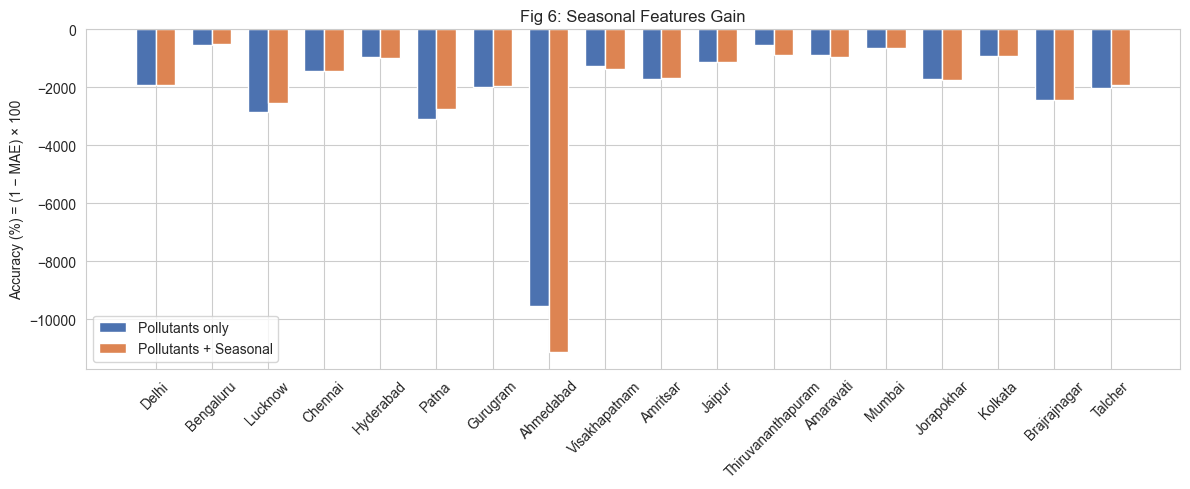

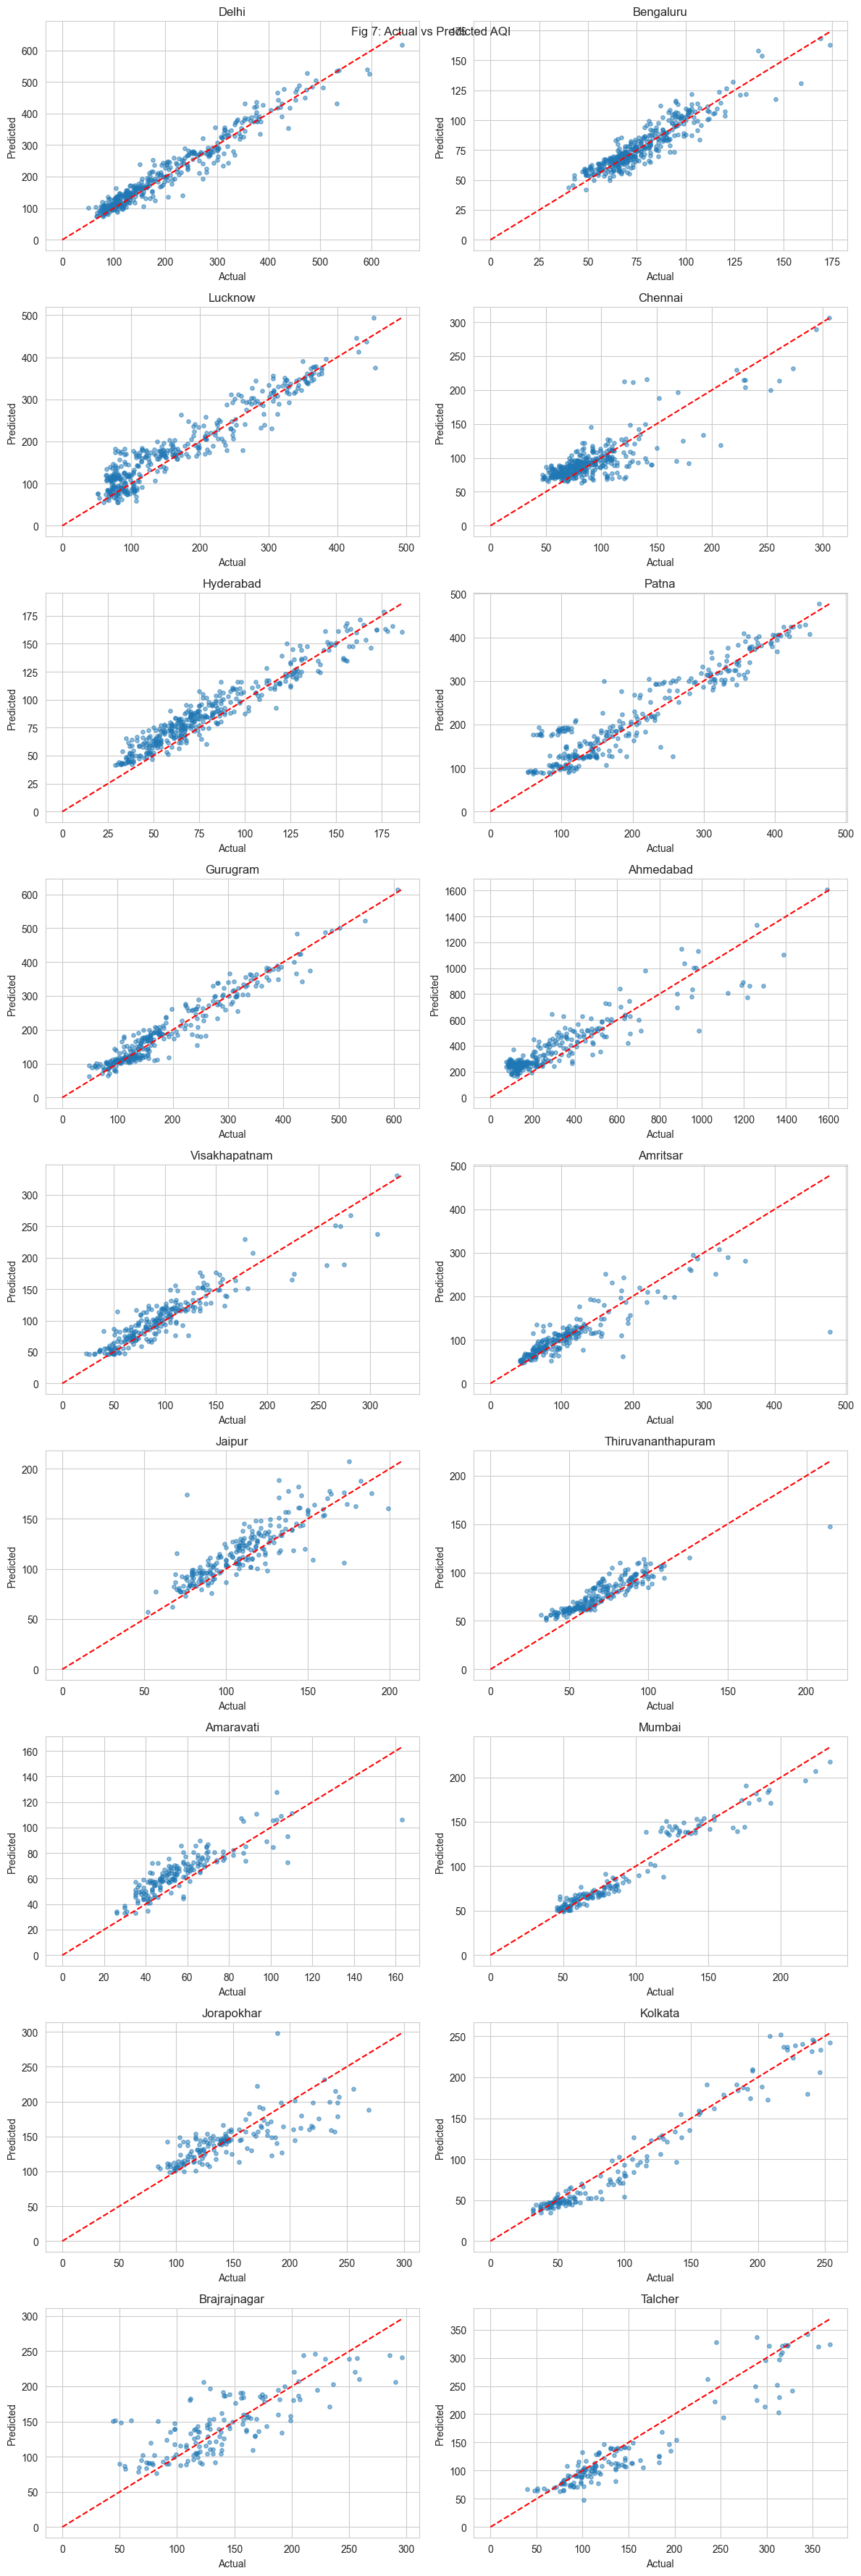

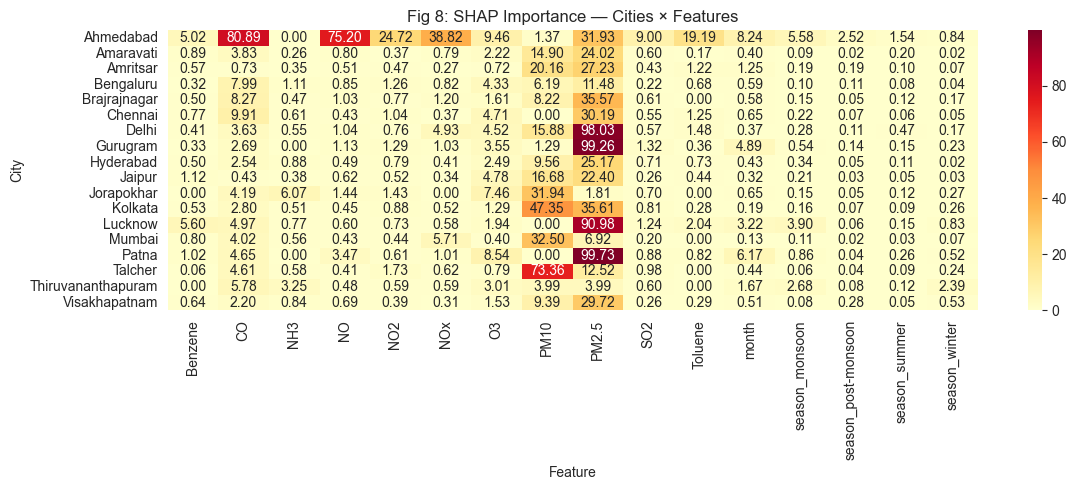

Best city: Bengaluru


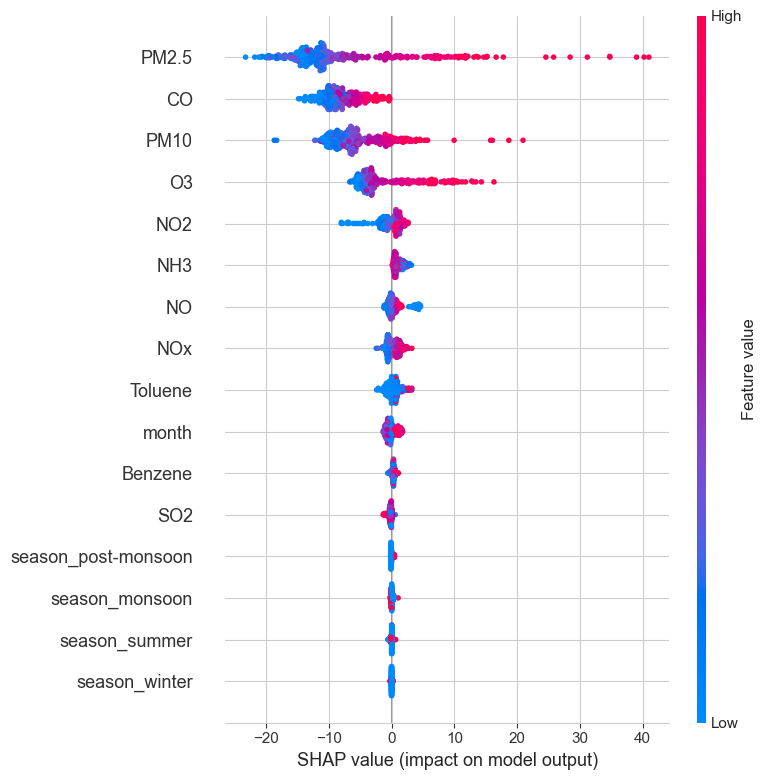

In [43]:
# Fig 6 — Seasonal gain
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(CITIES)); w = 0.35
a = [res_df[(res_df.City == c) & (res_df.Model == "RFR-tuned-poll")]["Accuracy"].values[0]     for c in CITIES]
b = [res_df[(res_df.City == c) & (res_df.Model == "RFR-tuned-seasonal")]["Accuracy"].values[0] for c in CITIES]
ax.bar(x - w/2, a, w, label="Pollutants only",       color="#4C72B0")
ax.bar(x + w/2, b, w, label="Pollutants + Seasonal", color="#DD8452")
ax.set_xticks(x); ax.set_xticklabels(CITIES, rotation=45)
ax.set_ylabel("Accuracy (%) = (1 − MAE) × 100")
ax.set_title("Fig 6: Seasonal Features Gain")
ax.legend(); plt.tight_layout(); plt.show()

# Fig 7 — Actual vs Predicted
n = len(CITIES); cols = 2; rows = (n + 1) // 2
fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows)); axes = axes.flatten()
for i, city in enumerate(CITIES):
    te  = splits[city]["test"]; art = best[city]["RFR-tuned-seasonal"]
    pr  = art["model"].predict(art["scaler"].transform(te[art["features"]].to_numpy(dtype=float)))
    axes[i].scatter(te["AQI"], pr, alpha=0.5, s=15)
    lim = [0, max(te["AQI"].max(), pr.max())]
    axes[i].plot(lim, lim, "r--")
    axes[i].set_title(city); axes[i].set_xlabel("Actual"); axes[i].set_ylabel("Predicted")
for j in range(n, len(axes)): axes[j].axis("off")
plt.suptitle("Fig 7: Actual vs Predicted AQI")
plt.tight_layout(); plt.show()

# Fig 8 — SHAP heatmap
shap_rows = []
for city in CITIES:
    art  = best[city]["RFR-tuned-seasonal"]
    X_te = art["scaler"].transform(splits[city]["test"][art["features"]].to_numpy(dtype=float))
    sv   = shap.TreeExplainer(art["model"]).shap_values(X_te)
    for feat, val in zip(art["features"], np.abs(sv).mean(axis=0)):
        shap_rows.append({"City": city, "Feature": feat, "SHAP": float(val)})

heat = pd.DataFrame(shap_rows).pivot(index="City", columns="Feature", values="SHAP").fillna(0)
plt.figure(figsize=(12, 5))
sns.heatmap(heat, cmap="YlOrRd", annot=True, fmt=".2f")
plt.title("Fig 8: SHAP Importance — Cities × Features")
plt.tight_layout(); plt.show()

# Fig 9 — Beeswarm for best city
top_city = (res_df[res_df.Model == "RFR-tuned-seasonal"]
            .sort_values("Accuracy", ascending=False).iloc[0]["City"])
art  = best[top_city]["RFR-tuned-seasonal"]
X_te = art["scaler"].transform(splits[top_city]["test"][art["features"]].to_numpy(dtype=float))
sv   = shap.TreeExplainer(art["model"]).shap_values(X_te)
print("Best city:", top_city)
shap.summary_plot(sv, X_te, feature_names=art["features"])

## 20 — `08_comparison_with_base_paper` + `09_save_models_and_summary`

In [44]:
# ---- Comparison with Gupta et al. ----
base_paper = pd.DataFrame({
    "City": ["New Delhi", "Bangalore", "Kolkata", "Hyderabad"],
    "Base_RFR_imbalanced": [79.4764, 67.7038, 90.9700, 78.3672],
    "Base_RFR_balanced":   [84.7284, 90.3071, 93.7438, 97.6080],
})

# Normalize names in case your dataset uses "Delhi" not "New Delhi"
name_map = {"Delhi": "New Delhi"}
your = (res_df[res_df.Model == "RFR-tuned-seasonal"][["City", "Accuracy"]]
        .rename(columns={"Accuracy": "Your_RFR_seasonal"}))
your["City"] = your["City"].replace(name_map)

comp = base_paper.merge(your, on="City", how="left")
comp["Δ_vs_imbalanced"] = comp["Your_RFR_seasonal"] - comp["Base_RFR_imbalanced"]
comp["Δ_vs_balanced"]   = comp["Your_RFR_seasonal"] - comp["Base_RFR_balanced"]

print("Comparison with Gupta et al. (2023):")
display(comp.round(2))

# ---- Save artifacts for Streamlit UI ----
for city in CITIES:
    art = best[city]["RFR-tuned-seasonal"]
    joblib.dump(art["model"],    f"{MODEL_DIR}/rfr_{city}.pkl")
    joblib.dump(art["scaler"],   f"{MODEL_DIR}/scaler_{city}.pkl")
    joblib.dump(art["features"], f"{MODEL_DIR}/features_{city}.pkl")

print("\nModels saved to:", os.path.abspath(MODEL_DIR))

# ---- Summary ----
mean_gain = (res_df[res_df.Model == "RFR-tuned-seasonal"]["Accuracy"].mean()
             - res_df[res_df.Model == "RFR-tuned-poll"]["Accuracy"].mean())

print("\n=== FINAL SUMMARY ===")
print(f"Cities analysed   : {len(CITIES)}")
print(f"Best accuracy     : {res_df['Accuracy'].max():.2f}%  "
      f"({res_df.loc[res_df['Accuracy'].idxmax(), 'City']})")
print(f"Mean seasonal gain: {mean_gain:.2f} pp")

Comparison with Gupta et al. (2023):


,City,Base_RFR_imbalanced,Base_RFR_balanced,Your_RFR_seasonal,Δ_vs_imbalanced,Δ_vs_balanced
0,New Delhi,79.48,84.73,-1932.60,-2012.08,-2017.33
1,Bangalore,67.70,90.31,NaN,NaN,NaN
2,Kolkata,90.97,93.74,-923.65,-1014.62,-1017.39
3,Hyderabad,78.37,97.61,-994.97,-1073.34,-1092.58



Models saved to: d:\Projects\air_quality_prediction\models

=== FINAL SUMMARY ===
Cities analysed   : 18
Best accuracy     : -504.79%  (Bengaluru)
Mean seasonal gain: -76.06 pp
